In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import warnings

warnings.filterwarnings("ignore")

# Настройка стиля графиков
sns.set_theme(style="whitegrid")

In [19]:
# Загрузка данных
file_path = 'particle_trajectories.csv'
df = pd.read_csv(file_path)
df.head()

,x0,v0,V0,x0_scale,gamma,trajectory_type
0,0.291241,-1.715540,1.32001,1.477050,0.138179,oscillating
1,0.969468,0.100859,1.54480,0.780300,0.453132,converging
2,-1.171810,1.829560,1.80002,1.188890,0.297068,oscillating
3,-1.877940,-0.574360,2.14310,0.879849,0.205815,oscillating
4,-1.942990,-2.104160,1.96396,1.197000,0.551000,oscillating


Распределение классов (абсолютные значения):
trajectory_type
converging     7423
diverging      7142
oscillating    5435
Name: count, dtype: int64

Доли классов:
trajectory_type
converging     0.37115
diverging      0.35710
oscillating    0.27175
Name: proportion, dtype: float64


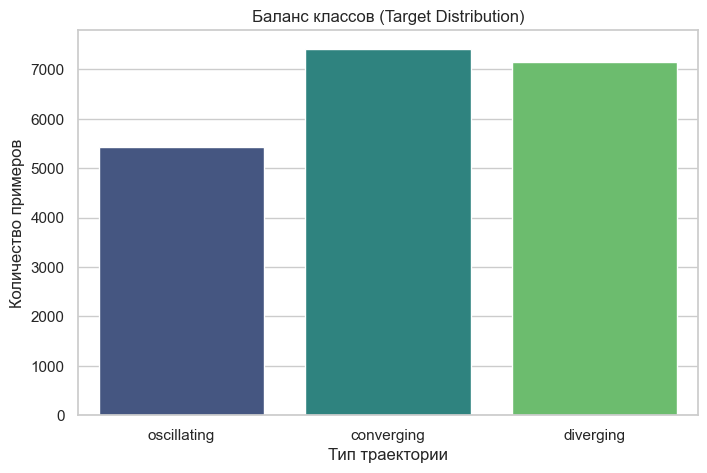

In [102]:
# Подсчет количества и доли каждого класса
class_counts = df['trajectory_type'].value_counts()
class_proportions = df['trajectory_type'].value_counts(normalize=True)

print("Распределение классов (абсолютные значения):")
print(class_counts)
print("\nДоли классов:")
print(class_proportions)

# Визуализация баланса классов
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='trajectory_type', palette='viridis')
plt.title('Баланс классов (Target Distribution)')
plt.ylabel('Количество примеров')
plt.xlabel('Тип траектории')
plt.show()

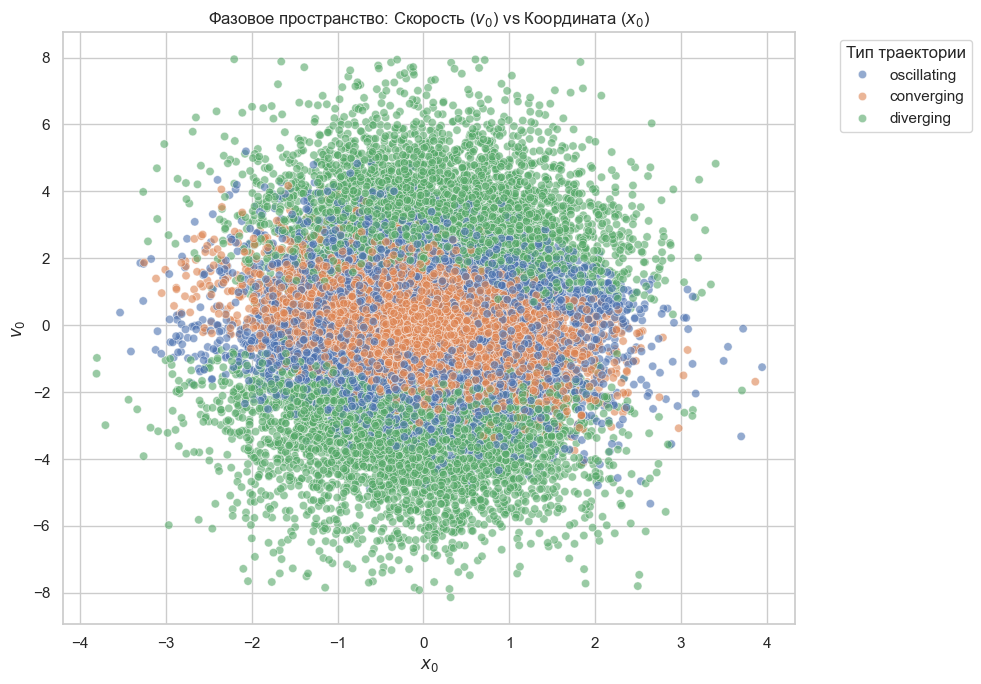

In [25]:
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=df, 
    x='x0', 
    y='v0', 
    hue='trajectory_type', 
    alpha=0.6, 
    palette='deep'
)
plt.title('Фазовое пространство: Скорость ($v_0$) vs Координата ($x_0$)')
plt.xlabel('$x_0$')
plt.ylabel('$v_0$')
plt.legend(title='Тип траектории', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

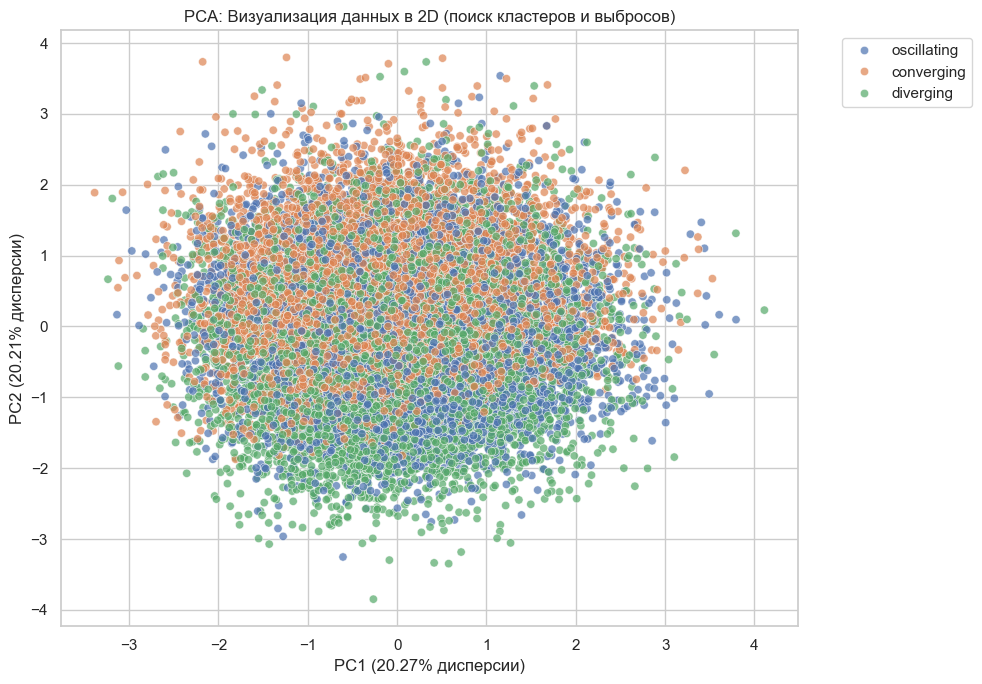

In [23]:
# 1. Отделяем признаки (X) от целевой переменной (y)
X = df[numeric_cols]
y = df['trajectory_type']

# 2. Стандартизация данных (обязательно перед PCA!)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Применение PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# Создаем DataFrame для удобства построения графика
pca_df = pd.DataFrame(data=X_pca, columns=['PC1', 'PC2'])
pca_df['trajectory_type'] = y.values

# 4. Визуализация PCA
plt.figure(figsize=(10, 7))
sns.scatterplot(
    data=pca_df, 
    x='PC1', 
    y='PC2', 
    hue='trajectory_type', 
    palette='deep',
    alpha=0.7
)
plt.title('PCA: Визуализация данных в 2D (поиск кластеров и выбросов)')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.2%} дисперсии)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.2%} дисперсии)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

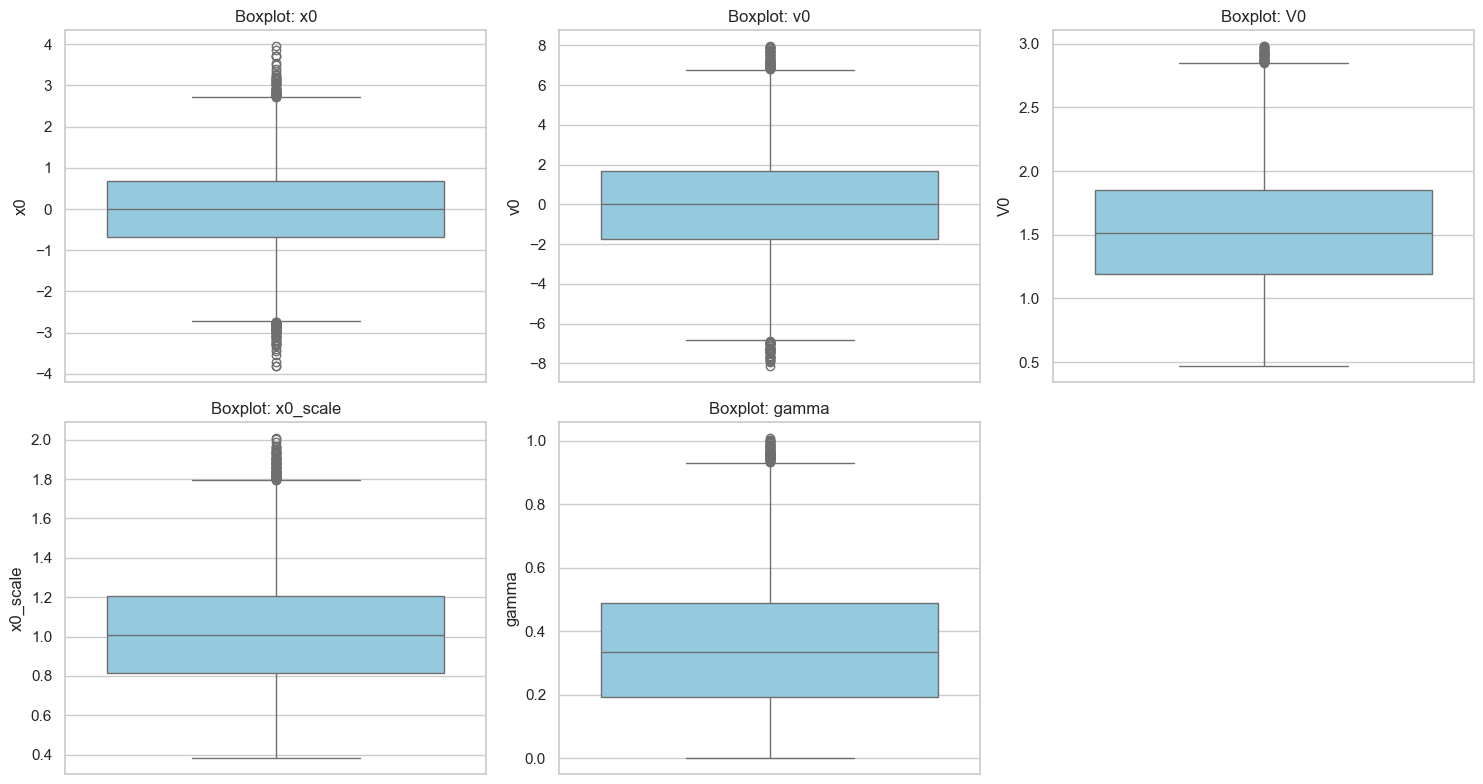

In [21]:
# Выбираем только числовые колонки для анализа
numeric_cols = ['x0', 'v0', 'V0', 'x0_scale', 'gamma']

plt.figure(figsize=(15, 8))
# Строим boxplot для каждого признака в одном ряду (предварительно нормализовав для наглядности, если масштабы разные)
# Но для поиска выбросов лучше смотреть на исходные масштабы по отдельности:

for i, col in enumerate(numeric_cols):
    plt.subplot(2, 3, i + 1)
    sns.boxplot(y=df[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [34]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
# 2. Кодирование целевой переменной (Target Encoding)
# Используем LabelEncoder, так как это задача классификации
le = LabelEncoder()
df['target_encoded'] = le.fit_transform(df['trajectory_type'])

# Выведем соответствие классов и чисел для проверки
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(f"Кодировка классов: {mapping}")

# Разделяем признаки (X) и целевую переменную (y)
X = df.drop(['trajectory_type', 'target_encoded'], axis=1)
y = df['target_encoded']

Кодировка классов: {'converging': 0, 'diverging': 1, 'oscillating': 2}


In [36]:
# 3. Разделение на обучающую и тестовую выборки
# test_size=0.3 -> 30% на тест
# stratify=y -> гарантирует, что доли классов в train и test будут такими же, как в исходном файле
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

In [38]:
# 4. Масштабирование признаков (Feature Scaling)
# Важно: fit (обучение скэлера) делаем ТОЛЬКО на train, чтобы избежать утечки данных!
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test) # К тесту применяем те же параметры, что выучили на трейне

# Преобразуем обратно в DataFrame для удобства (опционально, но полезно для просмотра)
X_train_scaled = pd.DataFrame(X_train_scaled, columns=X.columns)
X_test_scaled = pd.DataFrame(X_test_scaled, columns=X.columns)

# Проверка размеров
print("-" * 30)
print(f"Размер обучающей выборки (X_train): {X_train_scaled.shape}")
print(f"Размер тестовой выборки (X_test):  {X_test_scaled.shape}")
print("-" * 30)
print("Пример масштабированных данных (первые 3 строки X_train):")
print(X_train_scaled.head(3))

------------------------------
Размер обучающей выборки (X_train): (14000, 5)
Размер тестовой выборки (X_test):  (6000, 5)
------------------------------
Пример масштабированных данных (первые 3 строки X_train):
         x0        v0        V0  x0_scale     gamma
0  0.640320 -0.973089 -0.606074  0.053640  1.304941
1 -0.753333 -0.187567  2.353958 -0.723465  1.166302
2  1.254003  0.644544  1.335403  0.042183 -1.486132


In [52]:
# Импорт библиотек для обучения
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix, accuracy_score

In [48]:
model = LogisticRegression()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
LR_score = accuracy_score(y_test, y_pred)
print('Количество тестовых данных:', len(y_test))
print('Score:', LR_score)

pd.DataFrame(data = confusion_matrix(y_test, y_pred), columns=model.classes_, index=model.classes_)

Количество тестовых данных: 6000
Score: 0.5111666666666667


,0,1,2
0,1542,628,57
1,634,1416,93
2,572,949,109


In [50]:
model = RandomForestClassifier()
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
RFC_score = accuracy_score(y_test, y_pred)
print('Количество тестовых данных:', len(y_test))
print('Score:', RFC_score)

pd.DataFrame(data = confusion_matrix(y_test, y_pred), columns=model.classes_, index=model.classes_)

Количество тестовых данных: 6000
Score: 0.9346666666666666


,0,1,2
0,2127,1,99
1,0,2032,111
2,97,84,1449


In [112]:
model = MLPClassifier(
    hidden_layer_sizes=(50, 50), 
    max_iter=500, 
    activation='relu', 
    solver='adam', 
    random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
MLP_score = accuracy_score(y_test,y_pred)
print('Количество тестовых данных:', len(y_test))
print('Score:', MLP_score)

pd.DataFrame(data = confusion_matrix(y_test, y_pred), columns=model.classes_, index=model.classes_)

Количество тестовых данных: 6000
Score: 0.9636666666666667


,0,1,2
0,2169,0,58
1,0,2097,46
2,67,47,1516


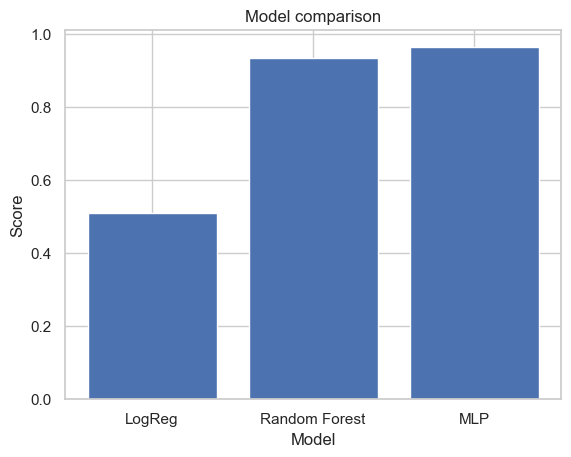

In [119]:
# Визуализация баланса классов
fig, ax = fig, ax = plt.subplots()
ax.bar(['LogReg', 'Random Forest', 'MLP'], [LR_score, RFC_score, MLP_score])
plt.title('Model comparison')
plt.ylabel('Score')
plt.xlabel('Model')
plt.show()

In [60]:
# Диапазоны гиперпараметров для Случайного леса
param_dist_rf = {
    'n_estimators': randint(50, 300),
    'max_depth': randint(5, 20),
    'min_samples_split': randint(2, 20),
    'min_samples_leaf': randint(1, 10),
    'criterion': ['gini', 'entropy']
}

# Инициализация RandomizedSearchCV
rf_tuned = RandomizedSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_distributions=param_dist_rf,
    n_iter=50, # Количество различных комбинаций для проверки
    cv=cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1, # Использование всех ядер процессора
    verbose=1
)

print("--- Настройка Random Forest ---")
rf_tuned.fit(X_train_scaled, y_train)

# Вывод лучших результатов
best_rf_params = rf_tuned.best_params_
best_rf_score = rf_tuned.best_score_

--- Настройка Random Forest ---
Fitting 5 folds for each of 50 candidates, totalling 250 fits


In [62]:
print(f"\n✅ Лучшая Accuracy на Кросс-валидации (RF): {best_rf_score:.4f}")
print(f"⚙️ Лучшая конфигурация (RF): {best_rf_params}")


✅ Лучшая Accuracy на Кросс-валидации (RF): 0.9223
⚙️ Лучшая конфигурация (RF): {'criterion': 'entropy', 'max_depth': 17, 'min_samples_leaf': 2, 'min_samples_split': 13, 'n_estimators': 211}


In [64]:
param_dist_mlp = {
    # Поиск среди разных архитектур: (100,), (50, 50), (100, 50, 25)
    'hidden_layer_sizes': [(np.random.randint(50, 150),), 
                           (np.random.randint(40, 80), np.random.randint(40, 80)),
                           (np.random.randint(80, 120), np.random.randint(40, 80), np.random.randint(20, 50))],
    'alpha': uniform(0.0001, 0.1), # L2 регуляризация
    'learning_rate_init': uniform(0.001, 0.1),
    'activation': ['tanh', 'relu'],
    'solver': ['adam']
}

# Инициализация RandomizedSearchCV
mlp_tuned = RandomizedSearchCV(
    estimator=MLPClassifier(max_iter=500, random_state=42),
    param_distributions=param_dist_mlp,
    n_iter=30, # Меньше итераций, так как обучение MLP дольше
    cv=cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("\n--- Настройка MLPClassifier ---")
# MLP чувствителен к размеру выборки, поэтому мы используем scaled данные
mlp_tuned.fit(X_train_scaled, y_train)

# Вывод лучших результатов
best_mlp_params = mlp_tuned.best_params_
best_mlp_score = mlp_tuned.best_score_

print(f"\n✅ Лучшая Accuracy на Кросс-валидации (MLP): {best_mlp_score:.4f}")
print(f"⚙️ Лучшая конфигурация (MLP): {best_mlp_params}")


--- Настройка MLPClassifier ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

✅ Лучшая Accuracy на Кросс-валидации (MLP): 0.9584
⚙️ Лучшая конфигурация (MLP): {'activation': 'relu', 'alpha': 0.05477102793432797, 'hidden_layer_sizes': (53, 62), 'learning_rate_init': 0.004131329245555858, 'solver': 'adam'}


In [66]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, uniform
import numpy as np

# Используем 5-кратную стратифицированную кросс-валидацию
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Диапазоны гиперпараметров для Логистической регрессии
param_dist_logreg = {
    # C (обратная сила регуляризации): ищем в логарифмическом масштабе, 
    # так как важен порядок величины (от 0.001 до 100)
    'C': loguniform(0.001, 100), 
    'penalty': ['l2', 'l1'], # L1 или L2 регуляризация
    'solver': ['liblinear', 'saga'] # Поддерживают L1 и L2
}

# Инициализация RandomizedSearchCV
logreg_tuned = RandomizedSearchCV(
    estimator=LogisticRegression(max_iter=1000, random_state=42),
    param_distributions=param_dist_logreg,
    n_iter=30, # Количество различных комбинаций для проверки
    cv=cv,
    scoring='accuracy',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("--- Настройка Логистической регрессии ---")
# Используем масштабированные данные
logreg_tuned.fit(X_train_scaled, y_train) 

# Вывод лучших результатов
best_logreg_params = logreg_tuned.best_params_
best_logreg_score = logreg_tuned.best_score_

print(f"\n✅ Лучшая Accuracy на Кросс-валидации (LogReg): {best_logreg_score:.4f}")
print(f"⚙️ Лучшая конфигурация (LogReg): {best_logreg_params}")

--- Настройка Логистической регрессии ---
Fitting 5 folds for each of 30 candidates, totalling 150 fits

✅ Лучшая Accuracy на Кросс-валидации (LogReg): 0.5203
⚙️ Лучшая конфигурация (LogReg): {'C': 0.033205591037519584, 'penalty': 'l1', 'solver': 'liblinear'}


## 1. Сводная таблица метрик на тестовой выборке
| Модель        |   Accuracy |   Balanced Accuracy |   F1-macro |
|:--------------|-----------:|--------------------:|-----------:|
| LogReg        |     0.5138 |              0.4729 |     0.4158 |
| Random Forest |     0.9322 |              0.9285 |     0.9277 |
| MLP           |     0.9542 |              0.9472 |     0.9502 |


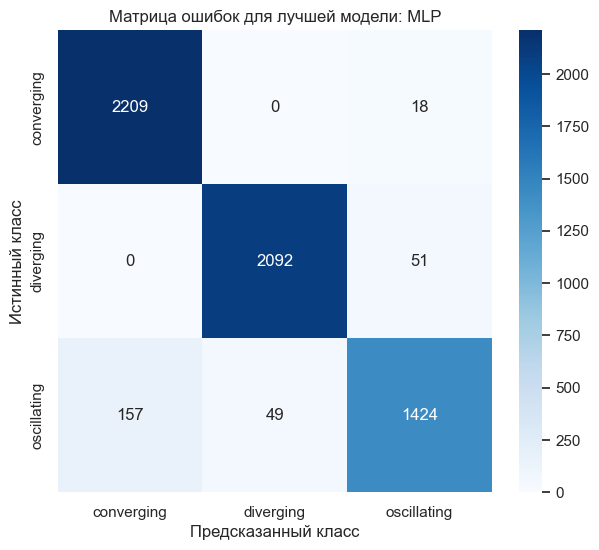

In [74]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score, confusion_matrix, classification_report

BEST_RF_PARAMS = {'criterion': 'entropy', 'max_depth': 17, 'min_samples_leaf': 2, 'min_samples_split': 13, 'n_estimators': 211}
BEST_MLP_PARAMS = {'activation': 'relu', 'alpha': 0.05477102793432797, 'hidden_layer_sizes': (53, 62), 'learning_rate_init': 0.004131329245555858, 'solver': 'adam'}
BEST_LOGREG_PARAMS = {'C': 0.033205591037519584, 'penalty': 'l1', 'solver': 'liblinear'}

# Инициализация и обучение финальных моделей
models = {
    'LogReg': LogisticRegression(max_iter=1000, random_state=42, **BEST_LOGREG_PARAMS),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1, **BEST_RF_PARAMS),
    'MLP': MLPClassifier(max_iter=500, random_state=42, **BEST_MLP_PARAMS)
}

# Словарь для хранения метрик
final_metrics = {}
y_preds = {}

# Обучение и оценка
for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_preds[name] = y_pred

    final_metrics[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'Balanced Accuracy': balanced_accuracy_score(y_test, y_pred),
        'F1-macro': f1_score(y_test, y_pred, average='macro'),
        'Confusion Matrix': confusion_matrix(y_test, y_pred)
    }

# Вывод сводной таблицы метрик
metrics_df = pd.DataFrame({
    'Модель': final_metrics.keys(),
    'Accuracy': [m['Accuracy'] for m in final_metrics.values()],
    'Balanced Accuracy': [m['Balanced Accuracy'] for m in final_metrics.values()],
    'F1-macro': [m['F1-macro'] for m in final_metrics.values()]
})

print("## 1. Сводная таблица метрик на тестовой выборке")
metrics_df['Accuracy'] = metrics_df['Accuracy'].map('{:.4f}'.format)
metrics_df['Balanced Accuracy'] = metrics_df['Balanced Accuracy'].map('{:.4f}'.format)
metrics_df['F1-macro'] = metrics_df['F1-macro'].map('{:.4f}'.format)
print(metrics_df.to_markdown(index=False))

# Визуализация Матриц ошибок (Confusion Matrix) для лучшей модели (напр., RF)
best_model_name = metrics_df.loc[metrics_df['Accuracy'].astype(float).idxmax(), 'Модель']
best_cm = final_metrics[best_model_name]['Confusion Matrix']

plt.figure(figsize=(7, 6))
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Матрица ошибок для лучшей модели: {best_model_name}')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()



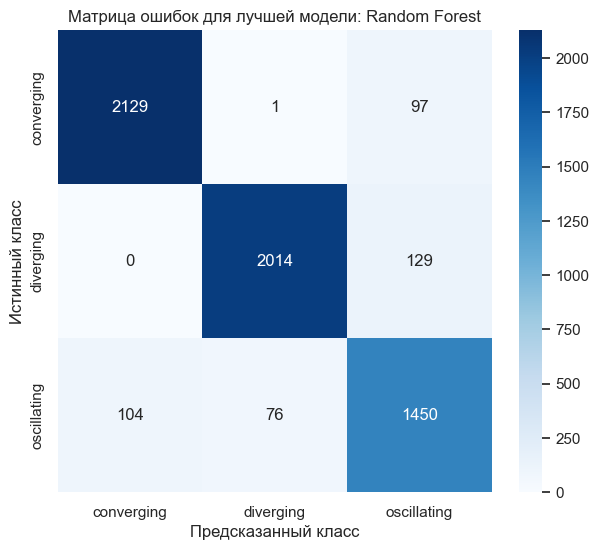

In [94]:
# Визуализация Матриц ошибок (Confusion Matrix) для лучшей модели (напр., RF)
best_model_name = 'Random Forest'
best_cm = final_metrics[best_model_name]['Confusion Matrix']

plt.figure(figsize=(7, 6))
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Матрица ошибок для лучшей модели: {best_model_name}')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

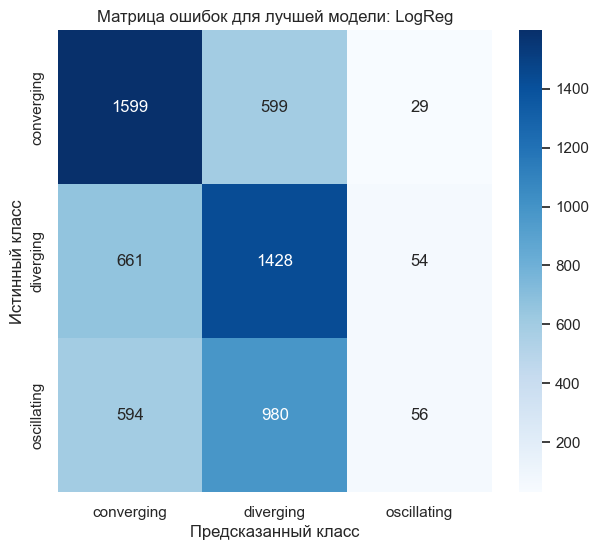

In [96]:
# Визуализация Матриц ошибок (Confusion Matrix) для лучшей модели (напр., RF)
best_model_name = 'LogReg'
best_cm = final_metrics[best_model_name]['Confusion Matrix']

plt.figure(figsize=(7, 6))
sns.heatmap(best_cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.title(f'Матрица ошибок для лучшей модели: {best_model_name}')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

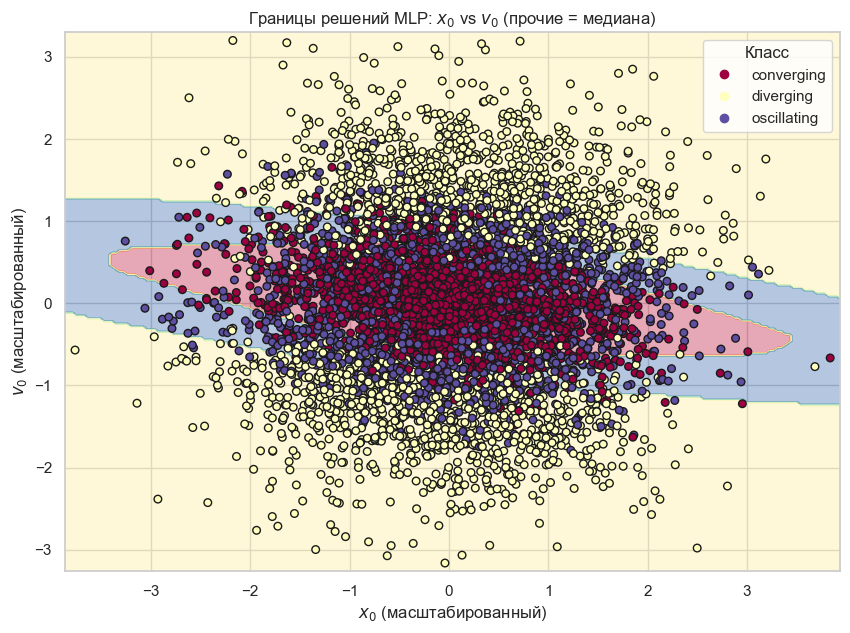

In [90]:
# Фиксируем лучшую модель (используем Random Forest в качестве примера)
best_model = models['MLP']

# Создаем "фиктивный" DataFrame из масштабированных данных
X_test_df = pd.DataFrame(X_test_scaled, columns=X.columns)

# Вычисляем медианы для фиксации остальных признаков
medians = X_test_df.median().values

# Определяем диапазон для построения сетки (Grid)
x_min, x_max = X_test_df['x0'].min() - 0.1, X_test_df['x0'].max() + 0.1
y_min, y_max = X_test_df['v0'].min() - 0.1, X_test_df['v0'].max() + 0.1

xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))

# Подготовка сетки для предсказания: фиксируем остальные признаки на медиане
grid = np.tile(medians, (xx.size, 1)) 
# Заменяем колонки x0 и v0 значениями сетки
grid[:, X.columns.get_loc('x0')] = xx.ravel()
grid[:, X.columns.get_loc('v0')] = yy.ravel()

# Предсказание на сетке
Z = best_model.predict(grid)
Z = Z.reshape(xx.shape)

# Визуализация
plt.figure(figsize=(10, 7))
plt.contourf(xx, yy, Z, alpha=0.4, cmap=plt.cm.Spectral)
scatter = plt.scatter(X_test_scaled['x0'], X_test_scaled['v0'], c=y_test, 
                      s=30, edgecolor='k', cmap=plt.cm.Spectral)

plt.title(f'Границы решений MLP: $x_0$ vs $v_0$ (прочие = медиана)')
plt.xlabel('$x_0$ (масштабированный)')
plt.ylabel('$v_0$ (масштабированный)')

# ИСПРАВЛЕНИЕ ОШИБКИ: Используем явное распаковывание и позиционные аргументы
legend_handles, _ = scatter.legend_elements()
plt.legend(legend_handles, le.classes_, title="Класс")

plt.show()